In [11]:

# 1. ALL IMPORTS
import os
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns


In [17]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:


import zipfile
import os

# Your zip file is in Drive
zip_path = '/content/drive/MyDrive/archive (2).zip'  # Use your actual filename
extract_path = '/content/dataset'

# Remove old extraction if exists
if os.path.exists(extract_path):
    import shutil
    shutil.rmtree(extract_path)

# Create folder and extract
os.makedirs(extract_path, exist_ok=True)

print("Extracting...")
with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_path)

print("✅ Extraction complete!")
print("Contents:", os.listdir(extract_path))

Extracting...
✅ Extraction complete!
Contents: ['Testing', 'Training']


In [19]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt

# 1. LOAD DATA - Simple and working
train_ds = keras.utils.image_dataset_from_directory(
    directory='/content/dataset/Training',  # After extraction
    labels='inferred',
    label_mode='categorical',
    batch_size=32,
    image_size=(224, 224),  # Smaller for faster training
    shuffle=True
)

validation_ds = keras.utils.image_dataset_from_directory(
    directory='/content/dataset/Testing',
    labels='inferred',
    label_mode='categorical',
    batch_size=32,
    image_size=(224, 224),
    shuffle=False
)

class_names = train_ds.class_names
print("Classes:", class_names)


Found 5600 files belonging to 4 classes.
Found 1600 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [20]:
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt

# 1. NORMALIZE YOUR DATA
def normalize(img, label):
    return tf.cast(img, tf.float32) / 255.0, label

train_ds = train_ds.map(normalize).prefetch(tf.data.AUTOTUNE)
validation_ds = validation_ds.map(normalize).prefetch(tf.data.AUTOTUNE)

In [21]:
# 2. BUILD THE MODEL
model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(256, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(4, activation='softmax')  # 4 classes
])


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [22]:
# 3. COMPILE THE MODEL
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("✅ Model Ready!")
model.summary()

✅ Model Ready!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,718,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,107,652 (19.48 MB)

 Trainable params: 5,107,652 (19.48 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
# 4. TRAIN THE MODEL
print("\n🔵 Training Started...")
history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=20,
    verbose=1
)



🔵 Training Started...
Epoch 1/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 25s 80ms/step - accuracy: 0.6671 - loss: 0.7698 - val_accuracy: 0.6756 - val_loss: 0.9633
Epoch 2/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 13s 71ms/step - accuracy: 0.8314 - loss: 0.4384 - val_accuracy: 0.7556 - val_loss: 0.8221
Epoch 3/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 13s 75ms/step - accuracy: 0.8771 - loss: 0.3240 - val_accuracy: 0.7556 - val_loss: 1.0348
Epoch 4/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 21s 75ms/step - accuracy: 0.9055 - loss: 0.2554 - val_accuracy: 0.8294 - val_loss: 0.9813
Epoch 5/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 21s 78ms/step - accuracy: 0.9279 - loss: 0.2005 - val_accuracy: 0.8431 - val_loss: 0.6879
Epoch 6/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 13s 73ms/step - accuracy: 0.9427 - loss: 0.1533 - val_accuracy: 0.8550 - val_loss: 0.8891
Epoch 7/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 20s 70ms/step - accuracy: 0.9534 - loss: 0.1381 - val_accuracy: 0.8550 - val_loss: 0.9241
Epoch 8/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 13s 73ms/step - accuracy: 0


📊 Evaluating...
✅ Test Accuracy: 89.00%
✅ Test Loss: 1.1905


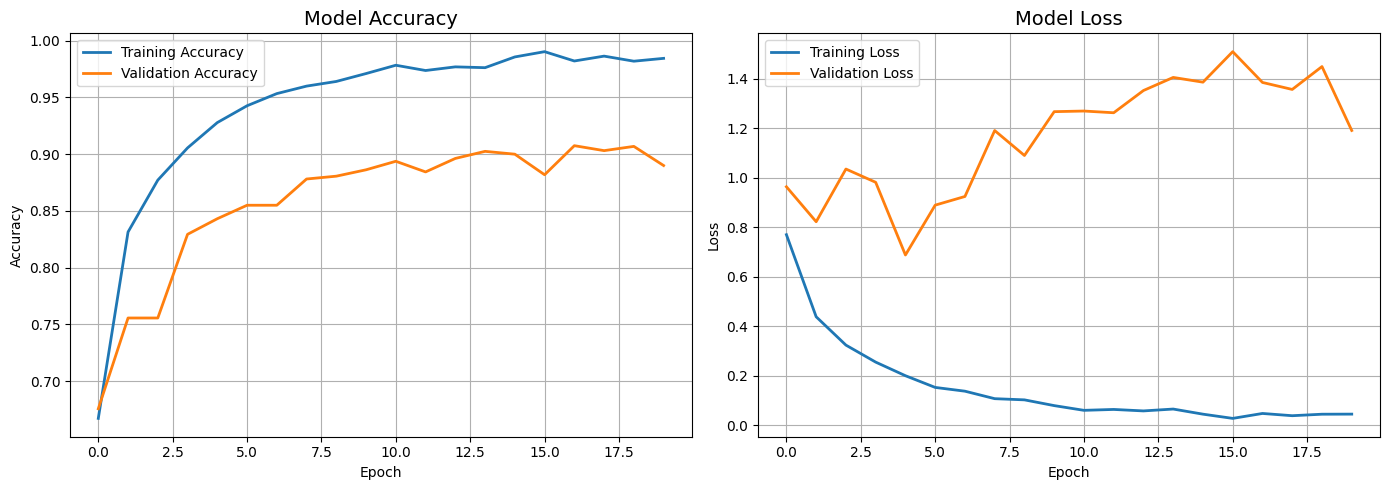

In [26]:
# 5. EVALUATE
print("\n📊 Evaluating...")
test_loss, test_acc = model.evaluate(validation_ds, verbose=0)
print(f"✅ Test Accuracy: {test_acc*100:.2f}%")
print(f"✅ Test Loss: {test_loss:.4f}")

# 6. PLOT RESULTS
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
ax1.set_title('Model Accuracy', fontsize=14)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

ax2.plot(history.history['loss'], label='Training Loss', linewidth=2)
ax2.plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
ax2.set_title('Model Loss', fontsize=14)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step

📊 CLASSIFICATION REPORT:
              precision    recall  f1-score   support

      glioma       0.89      0.78      0.83       400
  meningioma       0.84      0.89      0.86       400
     notumor       0.89      0.99      0.94       400
   pituitary       0.94      0.90      0.92       400

    accuracy                           0.89      1600
   macro avg       0.89      0.89      0.89      1600
weighted avg       0.89      0.89      0.89      1600



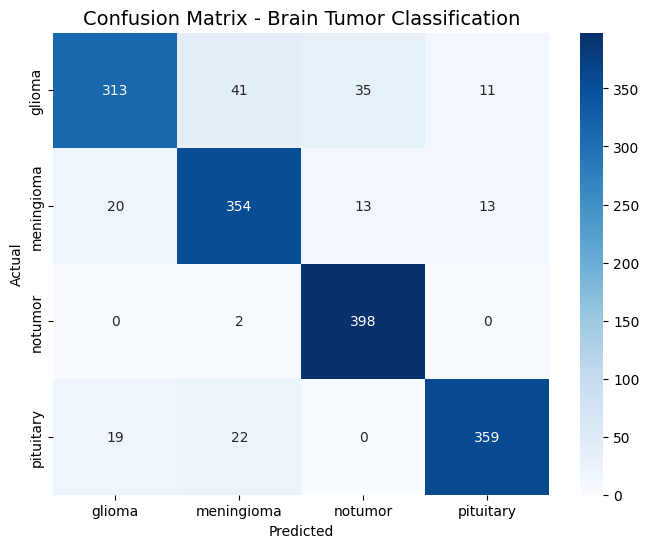


📈 PER-CLASS ACCURACY:
glioma: 78.25%
meningioma: 88.50%
notumor: 99.50%
pituitary: 89.75%


In [27]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Get predictions
y_pred = model.predict(validation_ds)
y_pred_classes = np.argmax(y_pred, axis=1)

# Get true labels
y_true = []
for _, labels in validation_ds:
    y_true.extend(np.argmax(labels.numpy(), axis=1))
y_true = np.array(y_true)

# 1. Classification Report
print("\n📊 CLASSIFICATION REPORT:")
print("="*50)
print(classification_report(y_true, y_pred_classes, target_names=class_names))

# 2. Confusion Matrix
cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Brain Tumor Classification', fontsize=14)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# 3. Per-Class Accuracy
print("\n📈 PER-CLASS ACCURACY:")
for i, name in enumerate(class_names):
    mask = (y_true == i)
    if np.sum(mask) > 0:
        acc = np.sum(y_pred_classes[mask] == i) / np.sum(mask)
        print(f"{name}: {acc*100:.2f}%")

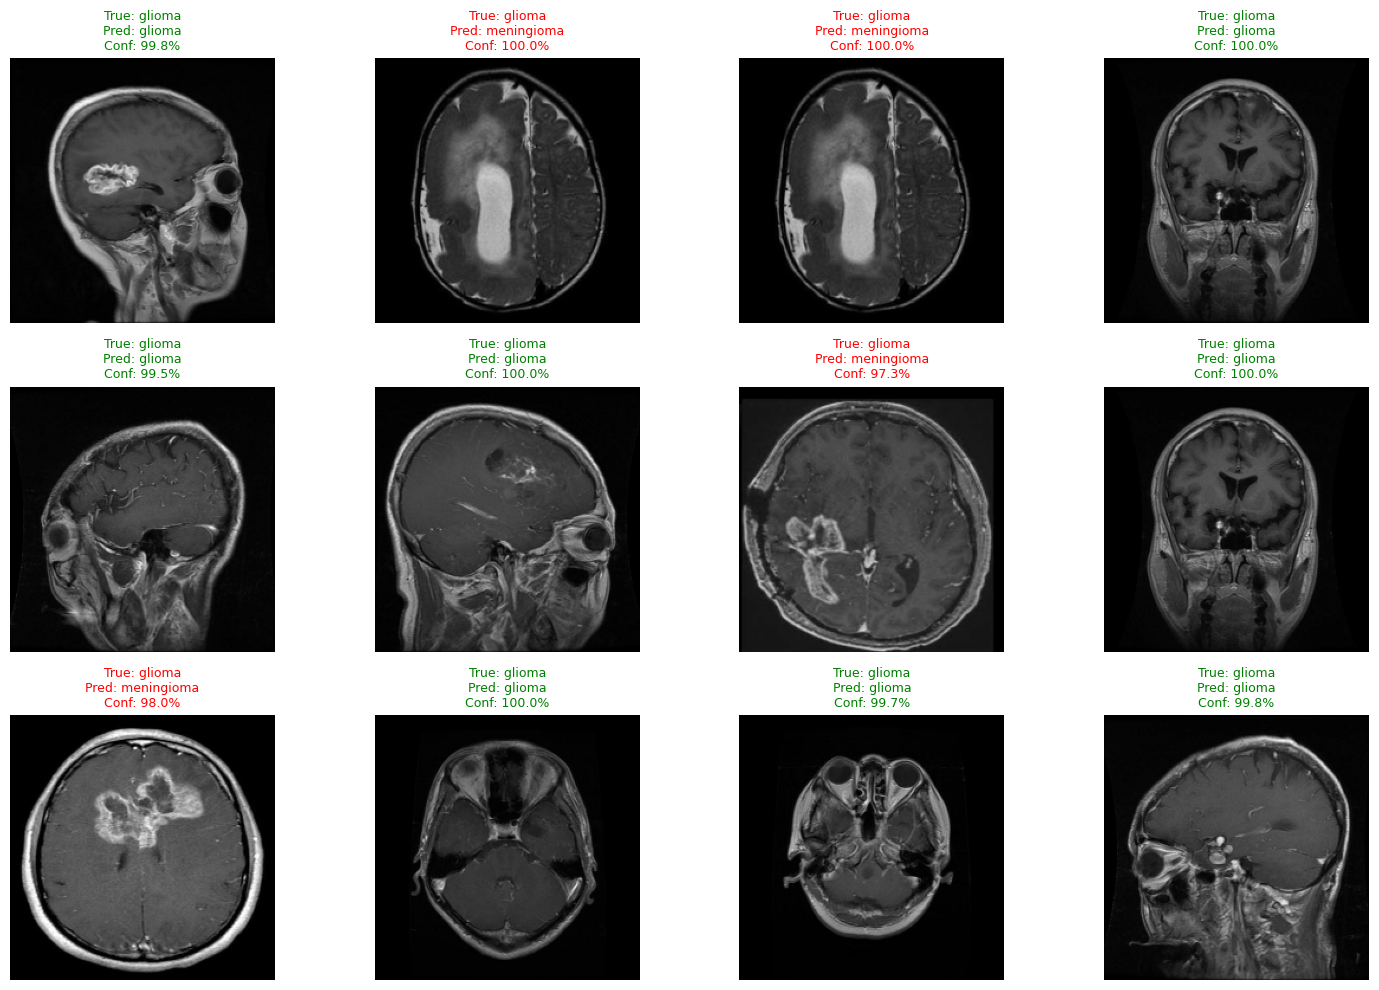

In [28]:
# Show sample predictions
plt.figure(figsize=(15, 10))

for i in range(12):
    plt.subplot(3, 4, i+1)

    # Get random image from validation set
    for images, labels in validation_ds.take(1):
        idx = np.random.randint(len(images))
        img = images[idx].numpy()
        true_label = np.argmax(labels[idx].numpy())

        # Predict
        pred = model.predict(np.expand_dims(img, axis=0), verbose=0)
        pred_label = np.argmax(pred)
        confidence = np.max(pred) * 100

        # Show image
        plt.imshow(img)
        color = 'green' if pred_label == true_label else 'red'
        plt.title(f'True: {class_names[true_label]}\nPred: {class_names[pred_label]}\nConf: {confidence:.1f}%',
                  color=color, fontsize=9)
        plt.axis('off')

plt.tight_layout()
plt.show()

In [29]:
# ===== SAVE YOUR MODEL =====
model.save('brain_tumor_model.h5')
print("✅ Model saved as 'brain_tumor_model.h5'")

✅ Model saved as 'brain_tumor_model.h5'


In [38]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import numpy as np

# Load the saved model
model = load_model('brain_tumor_model.h5')

class_names = ['glioma', 'meningioma', 'notumor', 'pituitary']

In [39]:
def predict_image(img_path):
    """
    Predict brain tumor from image
    """
    # Load image
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = img_array / 255.0  # Normalize
    img_array = np.expand_dims(img_array, axis=0)

    # Predict
    predictions = model.predict(img_array, verbose=0)
    pred_class = np.argmax(predictions)
    confidence = np.max(predictions) * 100

    # Result
    result = class_names[pred_class]
    is_tumor = result != 'notumor'

    return result, confidence, is_tumor, predictions


In [40]:
def display_prediction(img_path):
    """
    Display prediction with nice formatting
    """
    result, confidence, is_tumor, predictions = predict_image(img_path)

    print("="*50)
    print("🧠 BRAIN TUMOR DETECTION RESULT")
    print("="*50)

    if is_tumor:
        print(f"│  🚨 Tumor detected: YES                │")
        print(f"│  📊 Classification: {result.upper():<20} │")
        print(f"│  🎯 Confidence: {confidence:.1f}%              │")
    else:
        print(f"│  ✅ Tumor detected: NO                 │")
        print(f"│  📊 Classification: HEALTHY            │")
        print(f"│  🎯 Confidence: {confidence:.1f}%              │")

    print("="*50)

    # Show all class probabilities
    print("\n📊 Detailed Probabilities:")
    for i, name in enumerate(class_names):
        prob = predictions[0][i] * 100
        bar = "█" * int(prob/5)
        print(f"  {name:<12}: {prob:5.1f}% {bar}")

# ===== TEST WITH YOUR IMAGE =====
img_path = "/content/Te-no_28.jpg"  # Your image path
display_prediction(img_path)

🧠 BRAIN TUMOR DETECTION RESULT
│  ✅ Tumor detected: NO                 │
│  📊 Classification: HEALTHY            │
│  🎯 Confidence: 100.0%              │

📊 Detailed Probabilities:
  glioma      :   0.0% 
  meningioma  :   0.0% 
  notumor     : 100.0% ████████████████████
  pituitary   :   0.0% 
